# YOLO v11: распознавание людей для задания

Этот ноутбук подготовлен под задание: прогоняет предобученную YOLO v11 по 10 изображениям из папки `input_images` с порогом отсечения `conf=0.8`.

Считать в матрице ошибок нужно только класс `person` / людей. Остальные объекты не учитываются.


## 1. Установка и импорты

Запусти эту ячейку первой. Если `ultralytics` уже установлен, установка просто быстро завершится.


In [1]:
import warnings
warnings.filterwarnings('ignore')
warnings.simplefilter('ignore')

%pip install ultralytics==8.3.232

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from ultralytics import YOLO

import ultralytics
ultralytics.checks()


Ultralytics 8.3.232 🚀 Python-3.13.3 torch-2.12.0 CPU (Apple M1 Pro)
Setup complete ✅ (10 CPUs, 16.0 GB RAM, 425.8/460.4 GB disk)


## 2. Проверка исходных изображений

Картинки уже скачаны в папку `input_images`. Эта ячейка проверяет, что все 10 файлов на месте.


In [2]:
BASE_DIR = Path.cwd().resolve()

image_paths = [
    BASE_DIR / 'input_images/image_01_35.jpg',
    BASE_DIR / 'input_images/image_02_42.jpg',
    BASE_DIR / 'input_images/image_03_20.jpg',
    BASE_DIR / 'input_images/image_04_33.jpg',
    BASE_DIR / 'input_images/image_05_0.jpg',
    BASE_DIR / 'input_images/image_06_34.jpg',
    BASE_DIR / 'input_images/image_07_22.jpg',
    BASE_DIR / 'input_images/image_08_31.jpg',
    BASE_DIR / 'input_images/image_09_12.jpg',
    BASE_DIR / 'input_images/image_10_23.jpg',
]

missing = [str(path) for path in image_paths if not path.exists()]
if missing:
    raise FileNotFoundError('Не найдены файлы: ' + ', '.join(missing))

pd.DataFrame({
    'image': [path.name for path in image_paths],
    'path': [str(path) for path in image_paths],
})


,image,path
0,image_01_35.jpg,/Users/devianted/Desktop/Учёба/Обр Изо/input_...
1,image_02_42.jpg,/Users/devianted/Desktop/Учёба/Обр Изо/input_...
2,image_03_20.jpg,/Users/devianted/Desktop/Учёба/Обр Изо/input_...
3,image_04_33.jpg,/Users/devianted/Desktop/Учёба/Обр Изо/input_...
4,image_05_0.jpg,/Users/devianted/Desktop/Учёба/Обр Изо/input_...
5,image_06_34.jpg,/Users/devianted/Desktop/Учёба/Обр Изо/input_...
6,image_07_22.jpg,/Users/devianted/Desktop/Учёба/Обр Изо/input_...
7,image_08_31.jpg,/Users/devianted/Desktop/Учёба/Обр Изо/input_...
8,image_09_12.jpg,/Users/devianted/Desktop/Учёба/Обр Изо/input_...
9,image_10_23.jpg,/Users/devianted/Desktop/Учёба/Обр Изо/input_...


## 3. Загрузка модели

Используется предобученная модель `yolo11n.pt`. При первом запуске веса модели скачаются автоматически.


In [3]:
model = YOLO('yolo11n.pt')


## 4. Распознавание с порогом 80 процентов

Главный параметр задания здесь: `CONF = 0.8`. Результаты сохранятся в папку `runs/detect/yolo11_conf80`.


In [4]:
CONF = 0.8
output_project = BASE_DIR / 'runs' / 'detect'
output_name = 'yolo11_conf80'
save_dir = output_project / output_name

results = model(
    [str(path) for path in image_paths],
    save=True,
    conf=CONF,
    project=str(output_project),
    name=output_name,
    exist_ok=True,
)

rows = []
for path, result in zip(image_paths, results):
    detected_people = 0
    confidences = []

    for cls_id, confidence in zip(result.boxes.cls.tolist(), result.boxes.conf.tolist()):
        class_name = result.names[int(cls_id)]
        if class_name == 'person':
            detected_people += 1
            confidences.append(round(float(confidence), 3))

    rows.append({
        'image': path.name,
        'detected_people_by_yolo': detected_people,
        'person_confidences': confidences,
    })

summary = pd.DataFrame(rows)
display(summary)

print(f'Размеченные изображения сохранены в: {save_dir}')



0: 640x640 4 persons, 128.7ms
1: 640x640 4 persons, 128.7ms
2: 640x640 2 persons, 1 dog, 128.7ms
3: 640x640 4 persons, 128.7ms
4: 640x640 5 persons, 128.7ms
5: 640x640 3 persons, 128.7ms
6: 640x640 1 person, 128.7ms
7: 640x640 6 persons, 128.7ms
8: 640x640 4 persons, 128.7ms
9: 640x640 6 persons, 128.7ms
Speed: 3.6ms preprocess, 128.7ms inference, 3.7ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /Users/devianted/Desktop/Учёба/Обр Изо/runs/detect/yolo11_conf80


,image,detected_people_by_yolo,person_confidences
0,image_01_35.jpg,4,"[0.944, 0.938, 0.936, 0.905]"
1,image_02_42.jpg,4,"[0.913, 0.89, 0.866, 0.858]"
2,image_03_20.jpg,2,"[0.864, 0.808]"
3,image_04_33.jpg,4,"[0.914, 0.91, 0.871, 0.836]"
4,image_05_0.jpg,5,"[0.865, 0.86, 0.849, 0.821, 0.817]"
5,image_06_34.jpg,3,"[0.899, 0.849, 0.845]"
6,image_07_22.jpg,1,[0.821]
7,image_08_31.jpg,6,"[0.904, 0.885, 0.884, 0.866, 0.844, 0.838]"
8,image_09_12.jpg,4,"[0.936, 0.908, 0.88, 0.87]"
9,image_10_23.jpg,6,"[0.923, 0.916, 0.906, 0.906, 0.849, 0.841]"


Размеченные изображения сохранены в: /Users/devianted/Desktop/Учёба/Обр Изо/runs/detect/yolo11_conf80


## 5. Просмотр результатов

Синие рамки `person` считаются найденными людьми. Рамки других классов для задания игнорируются.


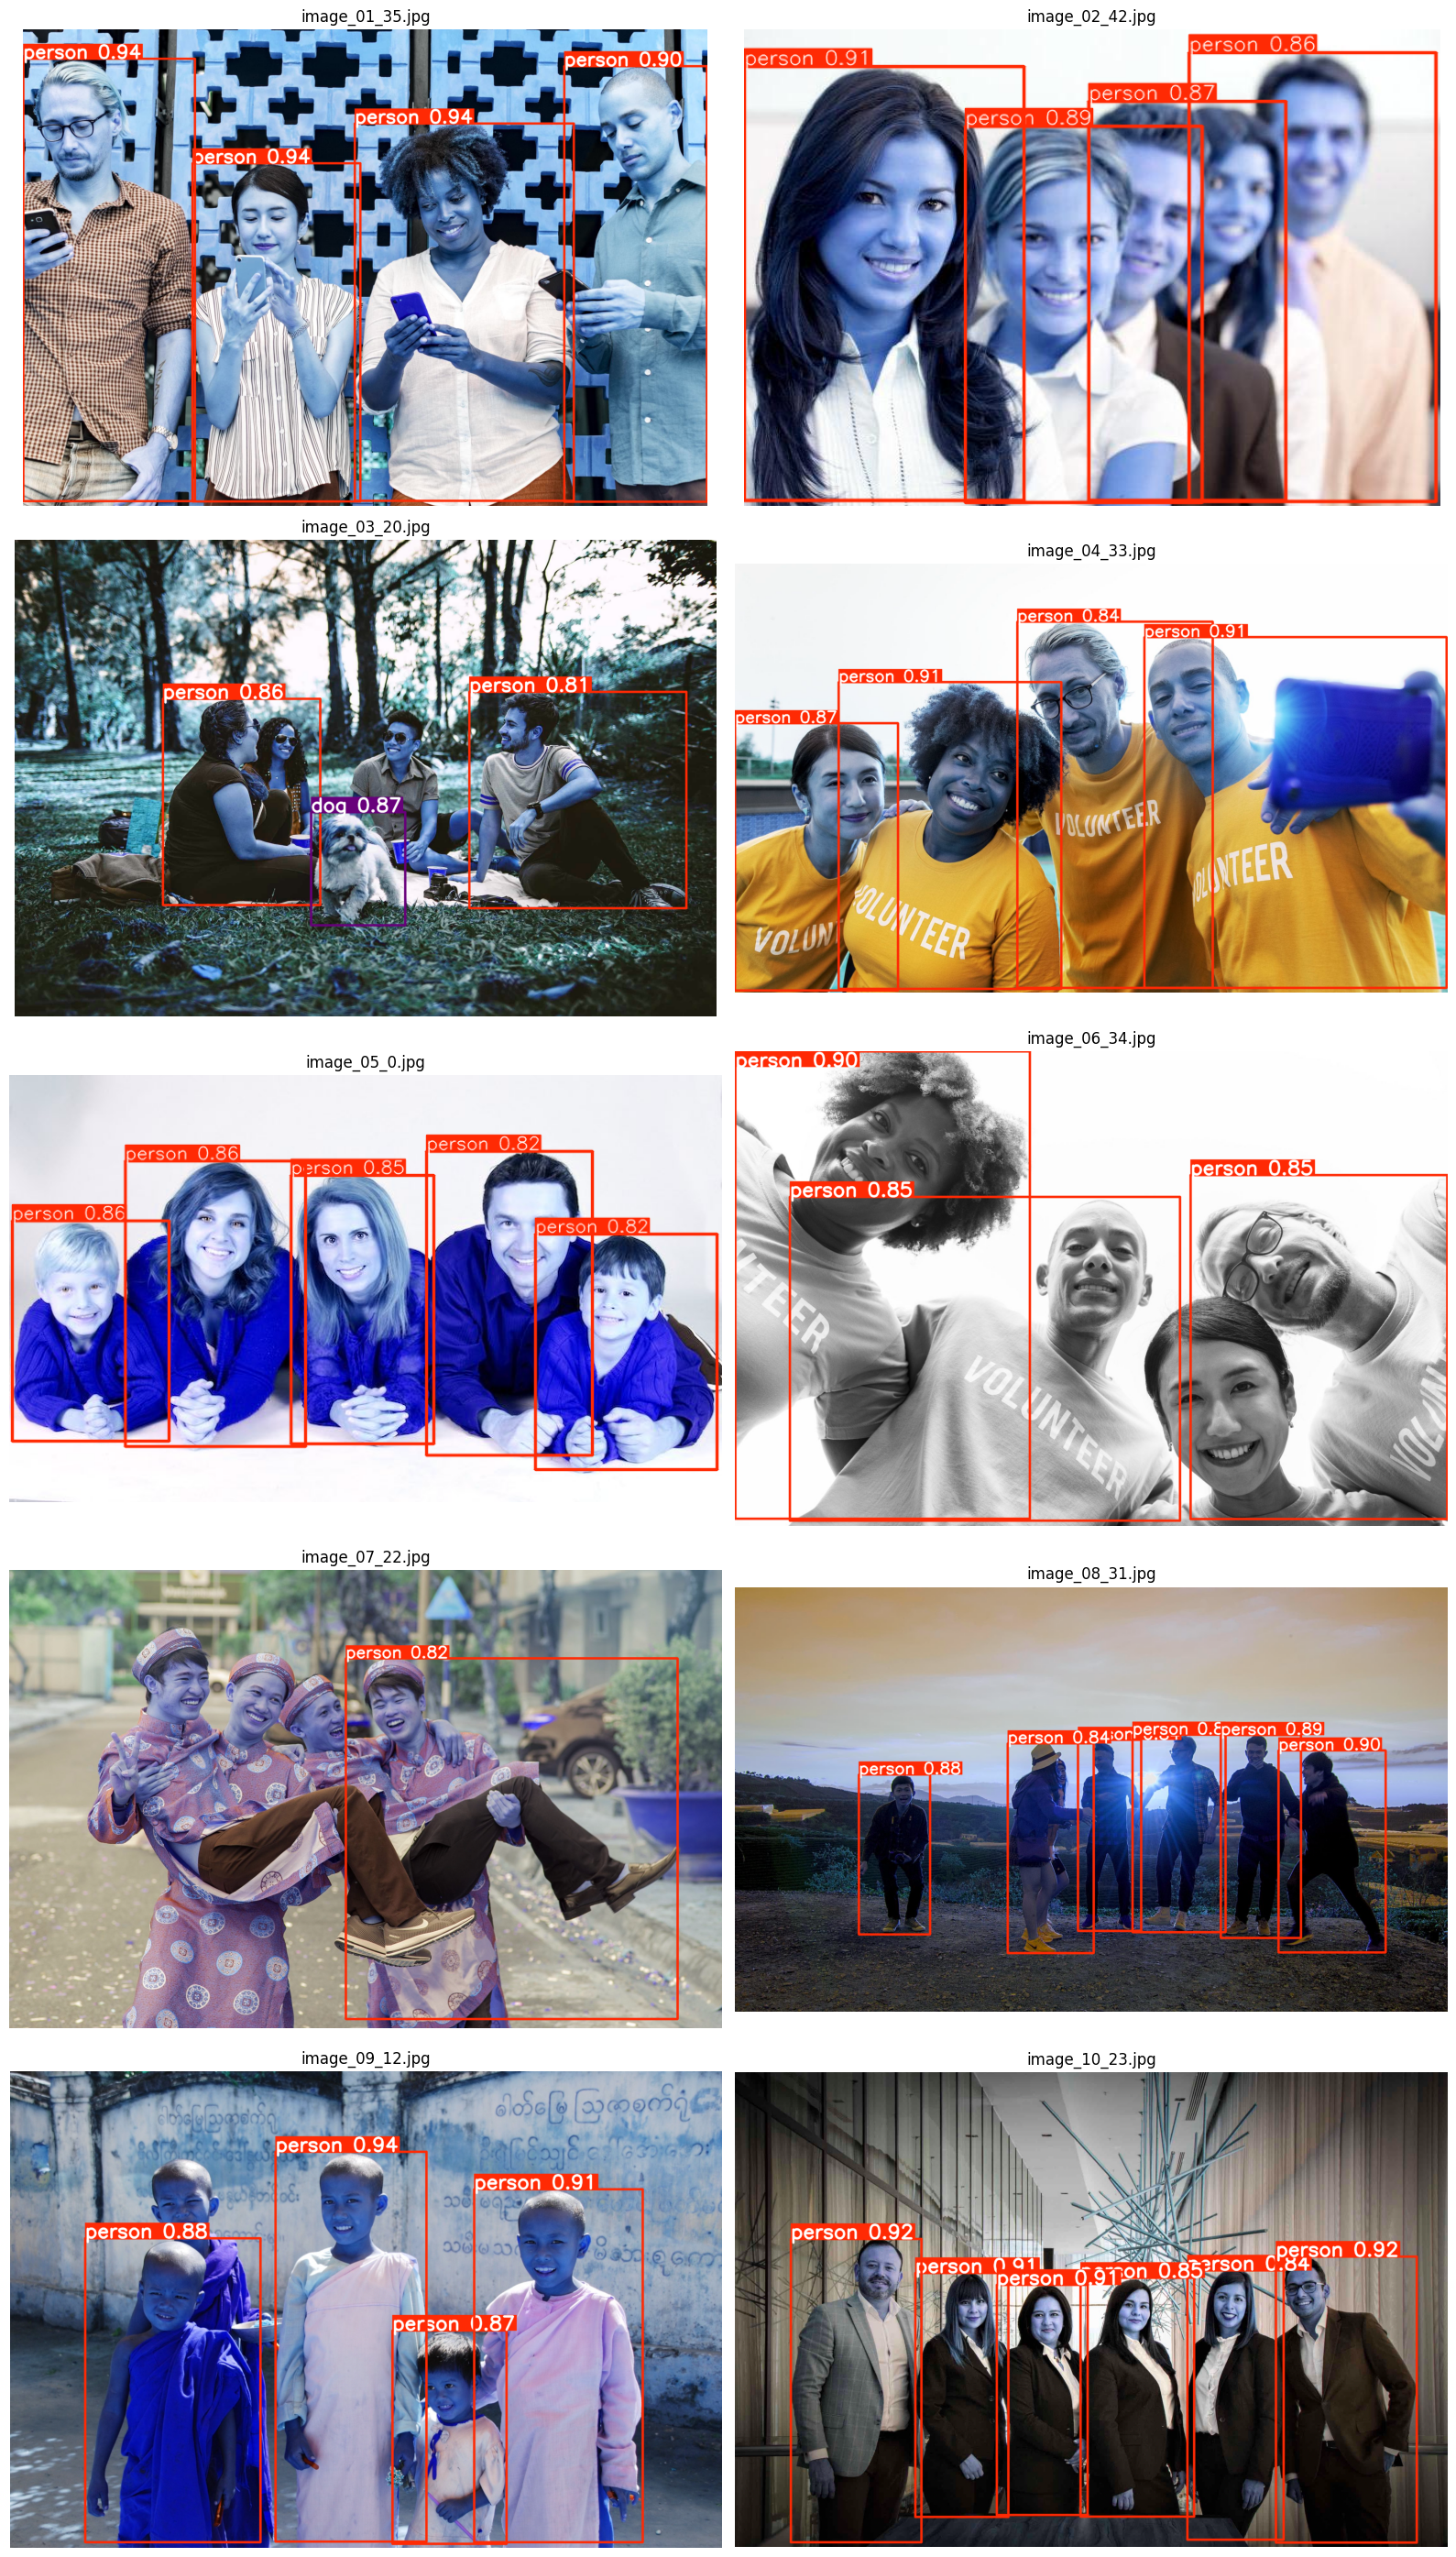

In [5]:
fig, axes = plt.subplots(5, 2, figsize=(16, 28))
axes = axes.ravel()

for ax, path, result in zip(axes, image_paths, results):
    # result.plot() возвращает уже размеченное изображение, поэтому не важно,
    # как YOLO назвала сохраненный файл в папке runs/detect.
    annotated_image = result.plot()
    ax.imshow(annotated_image)
    ax.set_title(path.name, fontsize=12)
    ax.axis('off')

plt.tight_layout()
plt.show()


## 6. Матрица ошибок

Теперь нужно глазами посчитать, сколько людей реально есть на каждой картинке, и заполнить список `actual_people` ниже.

Дополнительно посмотри, есть ли лишние рамки `person` на объектах, которые не являются людьми. Если есть, укажи их количество в `false_positive_person_boxes`. Обычно там будут нули.

Правила из задания:

- `TP` — модель нашла человека, и это действительно человек.
- `FP` — модель пометила объект как человека, но это не человек.
- `FN` — человек есть, но модель его не нашла.
- `TN` — всегда `0`.


In [6]:
# Впиши сюда количество реальных людей на каждой картинке по порядку image_01 ... image_10.
# Сейчас стоят None, чтобы случайно не получить неправильный ответ.
actual_people = [
    4,  # image_01_35.jpg
    5,  # image_02_42.jpg
    4,  # image_03_20.jpg
    4,  # image_04_33.jpg
    5,  # image_05_0.jpg
    4,  # image_06_34.jpg
    4,  # image_07_22.jpg
    6,  # image_08_31.jpg
    5,  # image_09_12.jpg
    6,  # image_10_23.jpg
]

# Сюда впиши количество лишних рамок person на НЕ-людях.
# Если таких ошибок нет, оставь 0.
false_positive_person_boxes = [
    0,  # image_01_35.jpg
    0,  # image_02_42.jpg
    0,  # image_03_20.jpg
    0,  # image_04_33.jpg
    0,  # image_05_0.jpg
    0,  # image_06_34.jpg
    0,  # image_07_22.jpg
    0,  # image_08_31.jpg
    0,  # image_09_12.jpg
    0,  # image_10_23.jpg
]

if any(value is None for value in actual_people):
    raise ValueError('Сначала заполни actual_people числами вместо None.')

metrics = summary.copy()
metrics['actual_people'] = actual_people
metrics['FP'] = false_positive_person_boxes
metrics['TP'] = metrics['detected_people_by_yolo'] - metrics['FP']
metrics['FN'] = metrics['actual_people'] - metrics['TP']
metrics['TN'] = 0

if (metrics[['TP', 'FP', 'FN']] < 0).any().any():
    raise ValueError('Проверь actual_people и false_positive_person_boxes: получились отрицательные TP/FP/FN.')

display(metrics[['image', 'actual_people', 'detected_people_by_yolo', 'TP', 'FP', 'FN', 'TN']])


,image,actual_people,detected_people_by_yolo,TP,FP,FN,TN
0,image_01_35.jpg,4,4,4,0,0,0
1,image_02_42.jpg,5,4,4,0,1,0
2,image_03_20.jpg,4,2,2,0,2,0
3,image_04_33.jpg,4,4,4,0,0,0
4,image_05_0.jpg,5,5,5,0,0,0
5,image_06_34.jpg,4,3,3,0,1,0
6,image_07_22.jpg,4,1,1,0,3,0
7,image_08_31.jpg,6,6,6,0,0,0
8,image_09_12.jpg,5,4,4,0,1,0
9,image_10_23.jpg,6,6,6,0,0,0


## 7. Precision, recall и F1

После заполнения `actual_people` запусти эту ячейку. Значение `F1` нужно округлить до тысячных и ввести в задание.


In [7]:
TP = int(metrics['TP'].sum())
FP = int(metrics['FP'].sum())
FN = int(metrics['FN'].sum())
TN = 0

precision = TP / (TP + FP) if TP + FP else 0
recall = TP / (TP + FN) if TP + FN else 0
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

confusion_matrix = pd.DataFrame(
    [[TP, FP], [FN, TN]],
    index=['Predicted True', 'Predicted False'],
    columns=['Actual True', 'Actual False'],
)

display(confusion_matrix)
print(f'TP = {TP}')
print(f'FP = {FP}')
print(f'FN = {FN}')
print(f'TN = {TN}')
print(f'precision = {precision:.3f}')
print(f'recall = {recall:.3f}')
print(f'F1 = {f1:.3f}')


,Actual True,Actual False
Predicted True,39,0
Predicted False,8,0


TP = 39
FP = 0
FN = 8
TN = 0
precision = 1.000
recall = 0.830
F1 = 0.907
